<a href="https://colab.research.google.com/github/feliciadominic14-create/Homework/blob/main/DataFrames.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [177]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [178]:
filepath='/content/Student_Depression_Dataset.csv'
df = pd.read_csv(filepath)
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [179]:
df.shape

(4464, 13)

In [180]:
df.columns

Index(['Gender', 'Age', 'Family_background', 'Relationship_status',
       'Marital_status', 'Living_style', 'Current_semester', 'CGPA',
       'friend_circle', 'Health_condition', 'Cost_without_study',
       'Home_division', 'Depression'],
      dtype='object')

In [181]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


In [182]:
df.isnull().sum()

,0
Gender,0
Age,0
Family_background,0
Relationship_status,0
Marital_status,0
Living_style,0
Current_semester,0
CGPA,0
friend_circle,0
Health_condition,0


In [183]:
df.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


In [184]:
df.duplicated().sum()

np.int64(0)

In [185]:
df.nunique()

,0
Gender,2
Age,12
Family_background,3
Relationship_status,3
Marital_status,3
Living_style,2
Current_semester,14
CGPA,169
friend_circle,2
Health_condition,4


In [186]:
df.dtypes

,0
Gender,object
Age,int64
Family_background,object
Relationship_status,object
Marital_status,object
Living_style,object
Current_semester,int64
CGPA,float64
friend_circle,object
Health_condition,object


#Data Frames:
###1.Numerical dataframe: missing values,duplicates,standardise
###2.Categorical dataframe:missing values,duplicates,encoding

In [187]:
num_df = df.select_dtypes(include=np.number)
cat_df = df.select_dtypes(include='object')
num_df.head()

,Age,Current_semester,CGPA,Cost_without_study
0,22,8,3.43,10113
1,19,2,3.70,13815
2,23,8,3.28,15450
3,20,2,3.77,17413
4,21,1,4.00,16693


In [188]:
cat_df.head()

,Gender,Family_background,Relationship_status,Marital_status,Living_style,friend_circle,Health_condition,Home_division,Depression
0,Female,Middle class,Single,Unmarried,Bachelor,Yes,Critical,Chittagong,Yes
1,Male,Middle class,Single,Unmarried,Bachelor,Yes,Abnormal,Chittagong,Yes
2,Male,Middle class,Single,Unmarried,Family,No,Abnormal,Dhaka,Yes
3,Male,Middle class,Complicated,Unmarried,Family,No,Good,Dhaka,No
4,Female,Middle class,Single,Unmarried,Family,No,Abnormal,Dhaka,Yes


In [189]:
#Numerical Dataframe
#check missing values
num_df.isna().sum()

,0
Age,0
Current_semester,0
CGPA,0
Cost_without_study,0


In [190]:
#handle missing vlues
num_df = num_df.fillna(num_df.median())

In [191]:
#check duplicates
df.duplicated().sum()

np.int64(0)

In [192]:
#remove duplicates if any
df.drop_duplicates(inplace=True)

In [193]:
df.duplicated().sum()

np.int64(0)

In [194]:
num_df = df.select_dtypes(include=np.number)
cat_df = df.select_dtypes(include='object')

In [195]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaled_data = scaler.fit_transform(num_df)
num_df = pd.DataFrame(
    scaled_data,
    columns=num_df.columns,
    index=num_df.index
)

In [196]:
num_df.head()

,Age,Current_semester,CGPA,Cost_without_study
0,-0.306105,1.007991,0.044732,-0.170193
1,-1.789232,-1.319225,0.745009,0.387388
2,0.188270,1.007991,-0.344311,0.633645
3,-1.294857,-1.319225,0.926563,0.929304
4,-0.800481,-1.707095,1.523095,0.820861


In [197]:
cat_df.isna().sum()

,0
Gender,0
Family_background,0
Relationship_status,0
Marital_status,0
Living_style,0
friend_circle,0
Health_condition,0
Home_division,0
Depression,0


#Label Encoding


In [198]:
from sklearn.preprocessing import LabelEncoder

In [199]:
encoder = LabelEncoder()

for col in cat_df.columns:
    cat_df[col] = encoder.fit_transform(cat_df[col])

In [200]:
cat_df.head()

,Gender,Family_background,Relationship_status,Marital_status,Living_style,friend_circle,Health_condition,Home_division,Depression
0,0,1,2,2,0,1,1,1,1
1,1,1,2,2,0,1,0,1,1
2,1,1,2,2,1,0,0,2,1
3,1,1,0,2,1,0,2,2,0
4,0,1,2,2,1,0,0,2,1


In [201]:
cat_df.nunique()

,0
Gender,2
Family_background,3
Relationship_status,3
Marital_status,3
Living_style,2
friend_circle,2
Health_condition,4
Home_division,8
Depression,2


In [202]:
df["Health_condition"].unique()

array(['Critical', 'Abnormal', 'Good', 'Normal'], dtype=object)

#Ordinal Encoder

In [203]:
from sklearn.preprocessing import OrdinalEncoder

In [204]:
encoder_health=OrdinalEncoder(categories=[["Normal","Good","Abnormal","Critical"]])

In [205]:
df["Health_condition"]=encoder_health.fit_transform(df[["Health_condition"]])

In [206]:
print(df[["Health_condition"]].drop_duplicates())

   Health_condition
0               3.0
1               2.0
3               1.0
5               0.0


In [207]:
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,3.0,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,2.0,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,2.0,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,1.0,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,2.0,16693,Dhaka,Yes


In [208]:
df["Family_background"].unique()

array(['Middle class', 'Lower Middle class', 'Rich class'], dtype=object)

In [209]:
encoder_family=OrdinalEncoder(categories=[["Lower Middle class","Middle class","Rich class"]])

In [210]:
df["Family_background"]=encoder_family.fit_transform(df[["Family_background"]])

In [211]:
print(df[["Family_background"]].drop_duplicates())

    Family_background
0                 1.0
6                 0.0
31                2.0


In [212]:
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,1.0,Single,Unmarried,Bachelor,8,3.43,Yes,3.0,10113,Chittagong,Yes
1,Male,19,1.0,Single,Unmarried,Bachelor,2,3.70,Yes,2.0,13815,Chittagong,Yes
2,Male,23,1.0,Single,Unmarried,Family,8,3.28,No,2.0,15450,Dhaka,Yes
3,Male,20,1.0,Complicated,Unmarried,Family,2,3.77,No,1.0,17413,Dhaka,No
4,Female,21,1.0,Single,Unmarried,Family,1,4.00,No,2.0,16693,Dhaka,Yes


In [213]:
df["Home_division"].value_counts()

,count
Home_division,
Dhaka,1527
Khulna,548
Rajshahi,488
Sylhet,445
Chittagong,400
Rangpur,363
Barisal,355
Mymensingh,338


In [215]:
#creating a column storing all numerical column names
num_Colmns=df.select_dtypes(include=["number"]).columns
#creating a column storing all categorical column names
Cat_colmns=df.select_dtypes(include=["object"]).columns
num_Colmns

Index(['Age', 'Family_background', 'Current_semester', 'CGPA',
       'Health_condition', 'Cost_without_study'],
      dtype='object')

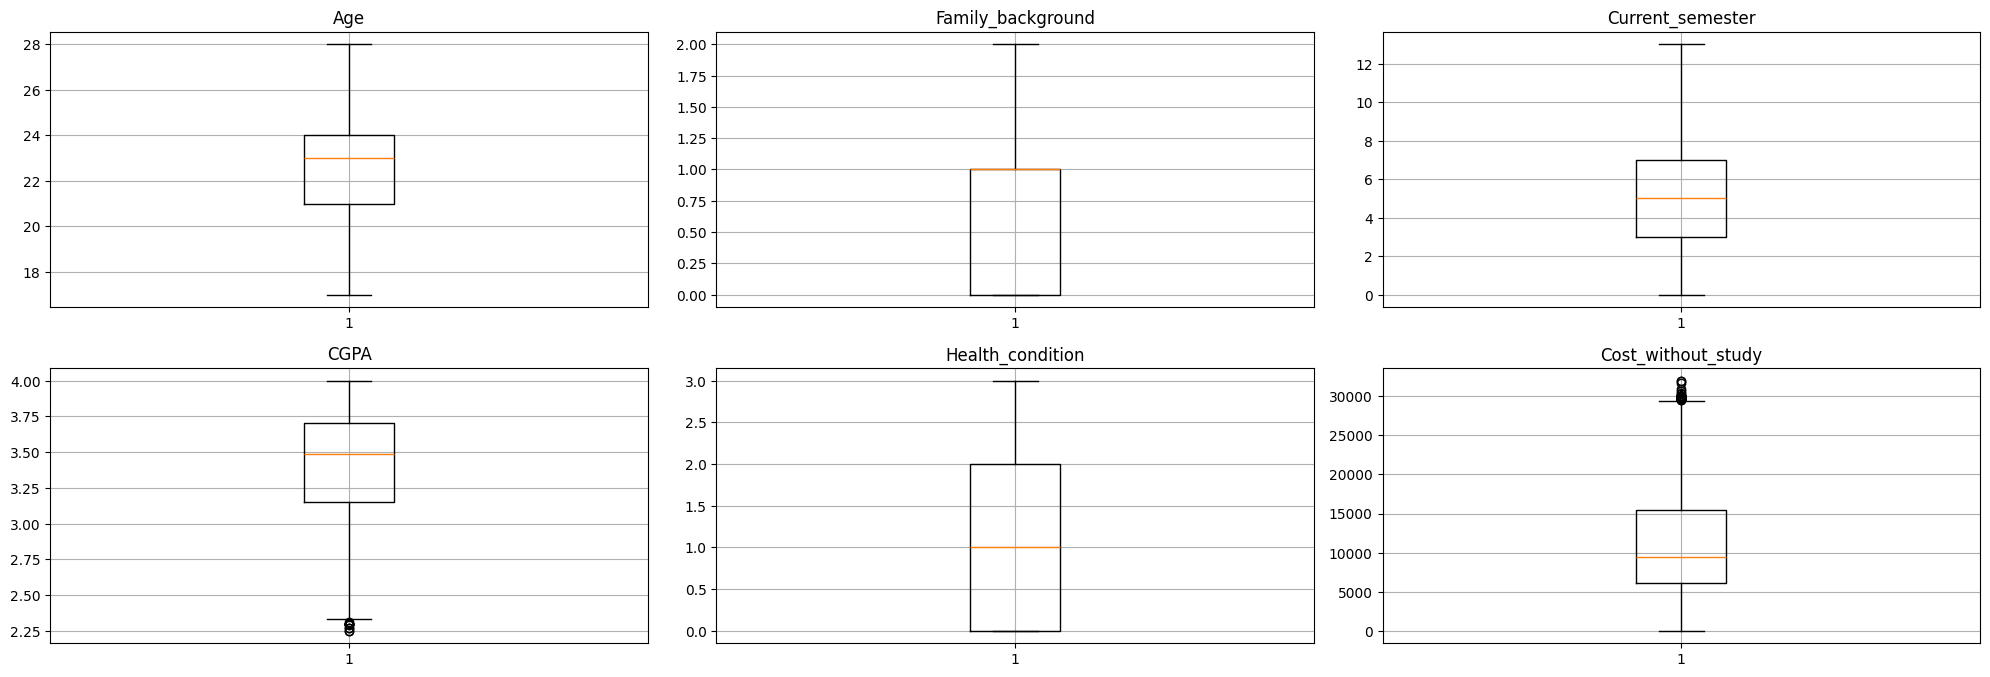

In [216]:
import matplotlib.pyplot as plt
plt.figure(figsize=(20, 10))
for i,col in enumerate(num_Colmns,1):
  plt.subplot(3,3,i)
  plt.boxplot(df[col].dropna())
  plt.title(col)
  plt.grid()
plt.tight_layout()
plt.show()

In [217]:
type(num_Colmns)

pandas.core.indexes.base.Index